# 07 · A character-level CNN on full URLs

v1 judges hostnames only, so it can't see phishing planted on hacked sites (`real-winery.com/wp-includes/...`). This notebook trains a deep model that reads the **whole URL**, one character at a time, on the leak-audited data from notebook 06.

```
url -> normalize -> character ids -> embedding -> 3 convolutions (3, 5, 7 chars wide)
    -> strongest match anywhere in the URL -> small network -> P(phishing)
```

Each convolution filter learns to fire on a short character pattern, such as `.php?`, `wp-includes`, `-verify`, or a random-looking hash. Max-pooling asks "did that pattern appear anywhere?"

The model has to clear three bars:
1. **The leak detector from notebook 06** (shape stats only). Beating it shows the CNN learned something beyond URL shape.
2. **A strong classical baseline**: TF-IDF character n-grams plus logistic regression, on the same full URLs.
3. **v1, on the real benchmark**, especially recall on non-platform phishing (46% to 72% for v1), which is where hacked sites live.

In [1]:
import json, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score

from phishdetect.data import PROJECT_ROOT
from phishdetect.features import split_host
from phishdetect.fullurl import normalize_full_url
from phishdetect.charcnn import CharCNNClassifier, best_device
from phishdetect.detector import PhishDetector
from phishdetect.benchmark import load_tranco, load_openphish, load_chrome_history, defang, RAW_DIR

pd.set_option("display.max_colwidth", 110)
RANDOM_STATE = 42
TARGET_FA = 0.05
SHOW_PRIVATE = False
DEVICE = best_device()
print("torch", torch.__version__, "| training on:", DEVICE)

torch 2.14.1 | training on: mps


`mps` means your Mac's GPU. `cpu` works too, just a few times slower.

## 0. Smoke test (about 30 seconds)
Train a tiny model for a few batches on made-up URLs. If anything is broken (PyTorch install, GPU support), it fails here instead of 20 minutes into the real run.

In [2]:
toy = ["vcu.edu/admissions", "github.com/a/b", "paypal-verify.xyz/login.php", "apple-id.top/signin.php"] * 64
toy_y = [0, 0, 1, 1] * 64
smoke = CharCNNClassifier(filters=16, embed_dim=8).fit(toy, toy_y, val_urls=toy[:8], val_y=toy_y[:8],
                                                       epochs=2, batch_size=32, device=DEVICE)
print("smoke test OK:", smoke.phish_proba(toy[:4]).round(3))

epoch  1  loss 0.6562  val PR-AUC 1.0000  (2s)
epoch  2  loss 0.5103  val PR-AUC 1.0000  (0s)
smoke test OK: [0.465 0.455 0.599 0.61 ]


## 1. Data from notebook 06

In [3]:
data = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "fullurl_dataset.csv.gz", keep_default_na=False)
data = data[data["text"].str.len() > 0]
card06 = json.loads((PROJECT_ROOT / "data" / "processed" / "fullurl_dataset.json").read_text())
LEAK_BAR = card06["leak_detector_pr_auc"]
splits = {s: data[data["split"] == s] for s in ["train", "val", "test"]}
for s, d in splits.items():
    print(f"{s:5s} {len(d):7,} URLs  {d['is_phishing'].mean():.1%} phishing  {d['registered'].nunique():,} domains")
print(f"\nleak detector bar from notebook 06: PR-AUC {LEAK_BAR:.3f}")

train  61,572 URLs  49.9% phishing  32,484 domains
val     7,293 URLs  53.3% phishing  4,060 domains
test    7,862 URLs  48.7% phishing  4,061 domains

leak detector bar from notebook 06: PR-AUC 0.891


The `text` column is already normalized, and `normalize_full_url` leaves it unchanged, so it's safe to pass it straight to the models.

## 2. Classical baseline: TF-IDF character n-grams
The same idea as model D from notebook 02, but on the full URL. Every 2 to 5 character chunk becomes a feature, and logistic regression weighs them. If the CNN can't beat this, the deep model isn't earning its complexity.

In [4]:
%%time
tfidf = make_pipeline(
    TfidfVectorizer(analyzer="char", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=300_000),
    LogisticRegression(max_iter=2000, C=4.0),
)
tfidf.fit(splits["train"]["text"], splits["train"]["is_phishing"])
for s in ["val", "test"]:
    p = tfidf.predict_proba(splits[s]["text"])[:, 1]
    print(f"TF-IDF {s} PR-AUC: {average_precision_score(splits[s]['is_phishing'], p):.4f}")

TF-IDF val PR-AUC: 0.9839
TF-IDF test PR-AUC: 0.9794
CPU times: user 6.67 s, sys: 181 ms, total: 6.85 s
Wall time: 6.87 s


## 3. Train the char-CNN
- **Early stopping**: after each epoch, score the validation set and keep the best epoch. Stop after 2 epochs without improvement.
- Expect about 1 to 3 minutes per epoch on the Mac GPU, depending on how much data the collector gathered.

In [5]:
%%time
cnn = CharCNNClassifier(embed_dim=48, filters=128, widths=(3, 5, 7), dropout=0.3, seed=RANDOM_STATE)
cnn.fit(splits["train"]["text"].tolist(), splits["train"]["is_phishing"].values,
        val_urls=splits["val"]["text"].tolist(), val_y=splits["val"]["is_phishing"].values,
        epochs=12, batch_size=256, lr=2e-3, patience=2, device=DEVICE)
print(f"{cnn.n_parameters():,} parameters, vocabulary of {len(cnn.vocab)} characters")

/Users/simess/Desktop/Projects/phishing-detector/src/phishdetect/charcnn.py:121: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  Y = torch.as_tensor(np.asarray(y), dtype=torch.float32)


epoch  1  loss 0.3251  val PR-AUC 0.9718  (15s)
epoch  2  loss 0.2044  val PR-AUC 0.9784  (15s)
epoch  3  loss 0.1559  val PR-AUC 0.9824  (15s)
epoch  4  loss 0.1263  val PR-AUC 0.9829  (15s)
epoch  5  loss 0.1068  val PR-AUC 0.9846  (15s)
epoch  6  loss 0.0903  val PR-AUC 0.9822  (15s)
epoch  7  loss 0.0847  val PR-AUC 0.9840  (15s)
no improvement for 2 epochs, stopping
122,769 parameters, vocabulary of 115 characters
CPU times: user 11.7 s, sys: 2.39 s, total: 14.1 s
Wall time: 1min 49s


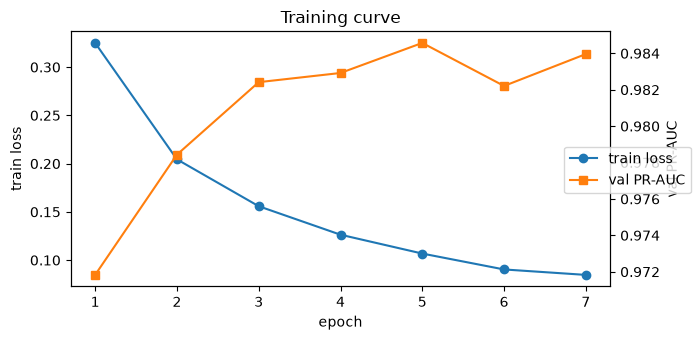

,train_loss,seconds,val_pr_auc
epoch,,,
1,0.3251,15.3331,0.9718
2,0.2044,14.6401,0.9784
3,0.1559,14.6960,0.9824
4,0.1263,14.6577,0.9829
5,0.1068,14.6367,0.9846
6,0.0903,14.8524,0.9822
7,0.0847,14.7586,0.9840


In [6]:
hist = pd.DataFrame(cnn.history).set_index("epoch")
fig, ax1 = plt.subplots(figsize=(7, 3.5))
hist["train_loss"].plot(ax=ax1, marker="o", label="train loss"); ax1.set_ylabel("train loss")
ax2 = ax1.twinx(); hist["val_pr_auc"].plot(ax=ax2, marker="s", color="tab:orange", label="val PR-AUC")
ax2.set_ylabel("val PR-AUC"); ax1.set_title("Training curve"); fig.legend(loc="center right"); plt.tight_layout(); plt.show()
hist.round(4)

Healthy: loss falls and validation PR-AUC rises, then flattens. If validation peaks early and drops while loss keeps falling, the model is memorizing (overfitting), and early stopping already kept the best epoch.

## 4. Test set: does the CNN clear the first two bars?

In [7]:
te = splits["test"]
test_scores = {
    "leak detector (notebook 06)": LEAK_BAR,
    "TF-IDF char n-grams": average_precision_score(te["is_phishing"], tfidf.predict_proba(te["text"])[:, 1]),
    "char-CNN": average_precision_score(te["is_phishing"], cnn.phish_proba(te["text"].tolist())),
}
pd.Series(test_scores, name="test PR-AUC").round(4).to_frame()

,test PR-AUC
leak detector (notebook 06),0.8908
TF-IDF char n-grams,0.9794
char-CNN,0.9746


The leak detector number comes from domain-grouped cross-validation on the whole dataset, not this exact test split, so treat that comparison as approximate. The CNN vs TF-IDF comparison is exact (same test URLs).

A big jump over the leak detector means the models learned the words, not just the shape. If the CNN only matches TF-IDF, that's still a real finding. The simpler model is cheaper to ship, and it goes in the journal.

## 5. What do the filters respond to?
Score URL fragments on their own to see which patterns the model reacts to. These are invented examples, not real URLs.

In [8]:
probes = ["example.com", "example.com/about/team", "example.com/login.php", "example.com/wp-includes/js/auth.php",
          "example.com/secure/verify/account", "example.com/index.html?id=8f3a9c2e7b1d",
          "paypal.com.example.com/signin", "example.com/blog/2024/10/hello-world"]
pd.DataFrame({"probe": probes, "char-CNN": cnn.phish_proba(probes).round(3),
              "TF-IDF": tfidf.predict_proba(probes)[:, 1].round(3)})

,probe,char-CNN,TF-IDF
0,example.com,0.385,0.274
1,example.com/about/team,0.004,0.030
2,example.com/login.php,0.992,0.999
3,example.com/wp-includes/js/auth.php,1.000,1.000
4,example.com/secure/verify/account,0.998,0.981
5,example.com/index.html?id=8f3a9c2e7b1d,0.892,0.683
6,paypal.com.example.com/signin,0.992,0.892
7,example.com/blog/2024/10/hello-world,0.000,0.003


## 6. The real test: the notebook 03 to 05 benchmark
Same benchmark as notebook 05, same domain-hash split into calibration and evaluation halves, same rule: pick each system's threshold on the calibration half at <= 5% false alarms on my history, then report on the evaluation half.

Systems compared:
- **v1**: the shipped detector (ensemble + allowlist)
- **char-CNN**: alone, no allowlist
- **char-CNN + allowlist**
- **v1 + char-CNN**: average of v1's two host models and the CNN, plus the allowlist (a candidate v2)

In [9]:
v1 = PhishDetector.load(PROJECT_ROOT / "models" / "detector_v1.joblib")

tranco  = load_tranco(n=5000, random_state=RANDOM_STATE)
phish   = load_openphish(path=sorted(RAW_DIR.glob("openphish_*.txt"))[-1])
history = load_chrome_history(n=1000, max_per_host=3, random_state=RANDOM_STATE)
bench = pd.concat([tranco, history, phish], ignore_index=True)
bench["is_phishing"] = bench["is_phishing"].astype(int)
parts = pd.DataFrame([split_host(u) for u in bench["url"]])
for c in ["registered", "platform"]:
    bench[c] = parts[c].values
bench["split"] = bench["registered"].map(
    lambda d: "calib" if int(hashlib.md5(d.encode()).hexdigest(), 16) % 2 == 0 else "eval")

# Safety check: no benchmark domain may appear in the stage 2 training data.
overlap = bench["registered"].isin(set(data["registered"]))
print(f"benchmark rows whose domain is in the training data: {overlap.sum()} (dropped)")
bench = bench[~overlap].reset_index(drop=True)
bench.groupby(["source", "split"]).size().unstack()

benchmark rows whose domain is in the training data: 0 (dropped)


split,calib,eval
source,,
history,226,172
openphish,135,165
tranco,2520,2480


Overlap should be 0 or close to it. Notebook 06 excluded benchmark domains, but if OpenPhish was downloaded again since then, a few new domains might overlap. They're dropped here either way.

In [10]:
%%time
urls = bench["url"].tolist()
host_scores = v1.model_scores(urls)                     # E+U (boosted) and D+U
bench["p::cnn"] = cnn.phish_proba(urls)
allow = np.array([v1.is_allowlisted(u) for u in urls])
bench["allowlisted"] = allow
bench["p::v1"] = v1.phish_proba(urls)
bench["p::cnn + allowlist"] = np.where(allow, 0.0, bench["p::cnn"])
bench["p::v1 + cnn"] = np.where(allow, 0.0, (host_scores.sum(axis=1).values + bench["p::cnn"]) / 3)

CPU times: user 1.13 s, sys: 941 ms, total: 2.07 s
Wall time: 1.13 s


In [11]:
def pick_threshold(legit_scores, target_fa):
    for t in np.sort(np.unique(np.r_[legit_scores, 1.0])):
        if (legit_scores >= t).mean() <= target_fa:
            return float(t)
    return 1.0

def rate(mask, flagged):
    return flagged[mask].mean() if mask.any() else np.nan

src = bench["source"]
cal, ev = bench["split"] == "calib", bench["split"] == "eval"
tail = bench["rank"] > 10_000
LEGIT = "history" if (src == "history").any() else "tranco"
systems = ["v1", "cnn", "cnn + allowlist", "v1 + cnn"]

rows, thresholds = [], {}
for s in systems:
    p = bench[f"p::{s}"]
    t = pick_threshold(p[cal & (src == LEGIT)].values, TARGET_FA)
    thresholds[s] = t
    f = p >= t
    rows.append({
        "system": s, "threshold": t,
        "history FA": rate(ev & (src == "history"), f),
        "Tranco tail FA": rate(ev & (src == "tranco") & tail, f),
        "recall": rate(ev & (src == "openphish"), f),
        "recall (platform)": rate(ev & (src == "openphish") & bench["platform"], f),
        "recall (other)": rate(ev & (src == "openphish") & ~bench["platform"], f),
    })
scoreboard = pd.DataFrame(rows).set_index("system").round(3)
scoreboard

,threshold,history FA,Tranco tail FA,recall,recall (platform),recall (other)
system,,,,,,
v1,0.310,0.058,0.301,0.915,1.000,0.803
cnn,1.000,0.041,0.002,0.255,0.362,0.113
cnn + allowlist,0.999,0.023,0.007,0.503,0.681,0.268
v1 + cnn,0.524,0.023,0.141,0.830,0.989,0.620


**The column to watch is recall (other)**: phishing that isn't on a free-hosting platform. Hacked legit sites live there, and v1 is weakest there. If the CNN raises it at the same false-alarm budget, stage 2 did its job.

Small-sample warning: the evaluation half has around 150 history URLs and around 150 OpenPhish URLs, so differences of a few points are noise.

## 7. What the CNN catches that v1 misses
Phishing URLs (defanged) where v1 said legit and v1 + CNN said phishing, at each system's threshold.

In [12]:
v1_flag = bench["p::v1"] >= thresholds["v1"]
v2_flag = bench["p::v1 + cnn"] >= thresholds["v1 + cnn"]
gained = bench[ev & (src == "openphish") & ~v1_flag & v2_flag][["url", "platform", "p::v1", "p::cnn"]].copy()
lost   = bench[ev & (src == "openphish") & v1_flag & ~v2_flag][["url", "platform", "p::v1", "p::cnn"]].copy()
for d in (gained, lost):
    d["url"] = d["url"].map(defang)
print(f"newly caught: {len(gained)}   newly missed: {len(lost)}")
display(gained.head(15))
display(lost.head(10))

newly caught: 0   newly missed: 14


,url,platform,p::v1,p::cnn


,url,platform,p::v1,p::cnn
5435,hxxp://roblox[.]com[.]gr/,False,0.342454,0.434774
5441,hxxps://gregarious-platforms-939712[.]framer[.]app/home-2,True,0.572066,0.287502
5464,hxxps://www[.]roblox[.]ss/communities/2886525628/Robux-Studios,False,0.448049,0.004471
5495,hxxps://posttp[.]com/,False,0.376201,0.774974
5510,hxxps://www[.]roblox[.]rw/games/14930532786/98xx-1M-VISITS?privateServerLinkCode=1104029018576654500574631...,False,0.397567,0.740920
5571,hxxp://www[.]similares[.]cl/,False,0.320920,0.522681
5580,hxxps://imtoke[.]net/dapp,False,0.395737,0.278147
5586,hxxp://www[.]roblox[.]rw/users/149150538518313/profile/,False,0.397567,0.290037
5594,hxxp://subscribe-spotify[.]com/,False,0.328826,0.837765
5613,hxxps://www[.]roblox[.]com[.]bn/games/2753915549/Blox-Fruits?privateServerLinkCode=47802401840295769168104...,False,0.441488,0.540502


In [13]:
h = bench[src == "history"]
if SHOW_PRIVATE:
    display(h.nlargest(15, "p::v1 + cnn")[["url", "p::v1", "p::cnn", "p::v1 + cnn"]])
else:
    print(f"{len(h)} history URLs. Flagged: v1 {(h['p::v1'] >= thresholds['v1']).sum()}, "
          f"v1 + cnn {(h['p::v1 + cnn'] >= thresholds['v1 + cnn']).sum()}")

398 history URLs. Flagged: v1 21, v1 + cnn 15


## 8. Save
The CNN by itself, plus a **candidate v2 detector** (v1's two host models and the CNN, the allowlist, and its calibrated threshold). The API keeps serving v1 until you decide v2 is better. To try v2 in the API:
```
PHISHDETECT_MODEL=models/detector_v2.joblib python -m uvicorn phishdetect.api:app --reload
```

In [14]:
import joblib
from datetime import date
joblib.dump(cnn, PROJECT_ROOT / "models" / "charcnn.joblib", compress=3)

v2 = PhishDetector(models={**v1.models, "char-CNN": cnn}, allowlist=v1.allowlist,
                   threshold=thresholds["v1 + cnn"], version="v2-candidate")
row = scoreboard.loc["v1 + cnn"]
v2.metadata = {
    "training_data": "v1 host models (PhiUSIIL + Umbrella) + char-CNN (Phishing.Database + Common Crawl)",
    "threshold_policy": f"lowest threshold with <= {TARGET_FA:.0%} false alarms on {LEGIT} (calibration half)",
    "eval_history_fa": row["history FA"], "eval_tranco_tail_fa": row["Tranco tail FA"],
    "eval_recall": row["recall"], "eval_recall_other": row["recall (other)"],
    "cnn_test_pr_auc": round(test_scores["char-CNN"], 4),
}
v2.save(PROJECT_ROOT / "models" / "detector_v2.joblib")

# sanity check: the saved file loads and explains a URL, like the API will
print(PhishDetector.load(PROJECT_ROOT / "models" / "detector_v2.joblib").explain("http://example.com/wp-includes/js/auth.php"))

(PROJECT_ROOT / "reports").mkdir(exist_ok=True)
scoreboard.assign(notebook="07", date=date.today().isoformat(), target_fa=TARGET_FA).to_csv(
    PROJECT_ROOT / "reports" / "scoreboard_07.csv")

{'url': 'http://example.com/wp-includes/js/auth.php', 'host': 'example.com', 'registered_domain': 'example.com', 'verdict': 'legit', 'score': 0.0, 'threshold': 0.5244915041014939, 'allowlisted': True, 'model_scores': {'E+U (boosted)': 0.193, 'D+U': 0.043, 'char-CNN': 1.0}, 'reasons': ['example.com is on the popular-domain allowlist']}


## Results log
| | test PR-AUC |
|---|---|
| leak detector | |
| TF-IDF char n-grams | |
| char-CNN | |

| system | history FA | Tranco tail FA | recall | recall (platform) | recall (other) |
|---|---|---|---|---|---|
| v1 | | | | | |
| cnn | | | | | |
| cnn + allowlist | | | | | |
| v1 + cnn | | | | | |

Questions for the journal:
1. Did the CNN beat the leak detector and TF-IDF on the test set? By how much?
2. On the benchmark, did v1 + CNN raise recall on non-platform phishing at the same false-alarm budget?
3. What kinds of URLs did it newly catch, and what did it newly miss?
4. Is v2 worth shipping? (Consider: PyTorch makes the Docker image much bigger.)